# Visualize features

### Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fnirsatlas.utils import get_processed_data_path
from fnirsatlas.processed_dataset import load_processed_dataset
from fnirsatlas.load_parser import load_parser
from fnirsatlas.feature_extraction import WindowedFeatureExtractor

### Load dataset

In [2]:
# Load BNCI dataset
print("Loading BNCI dataset...")
dataset_file = get_processed_data_path("bnci")
X, y, groups, info = load_processed_dataset(dataset_file)
parser = load_parser("bnci", download="no")

X = X[:5]
y = y[:5]

print(f"Data shape: {X.shape}")

Loading BNCI dataset...
Data shape: (5, 104, 76)


### Normalize channels for consistent visualization

In [3]:
X_norm = np.zeros_like(X)
for trial in range(X.shape[0]):
    for ch in range(X.shape[1]):
        mean_val = np.mean(X[trial, ch, :])
        std_val = np.std(X[trial, ch, :])
        if std_val > 0:
            X_norm[trial, ch, :] = (X[trial, ch, :] - mean_val) / std_val
        else:
            X_norm[trial, ch, :] = X[trial, ch, :] - mean_val

### Extract features with 6 windows from normalized data

In [4]:
extractor = WindowedFeatureExtractor(n_windows=6, features=["mean", "std", "slope"])
X_features = extractor.transform(X_norm)

### Visualize features

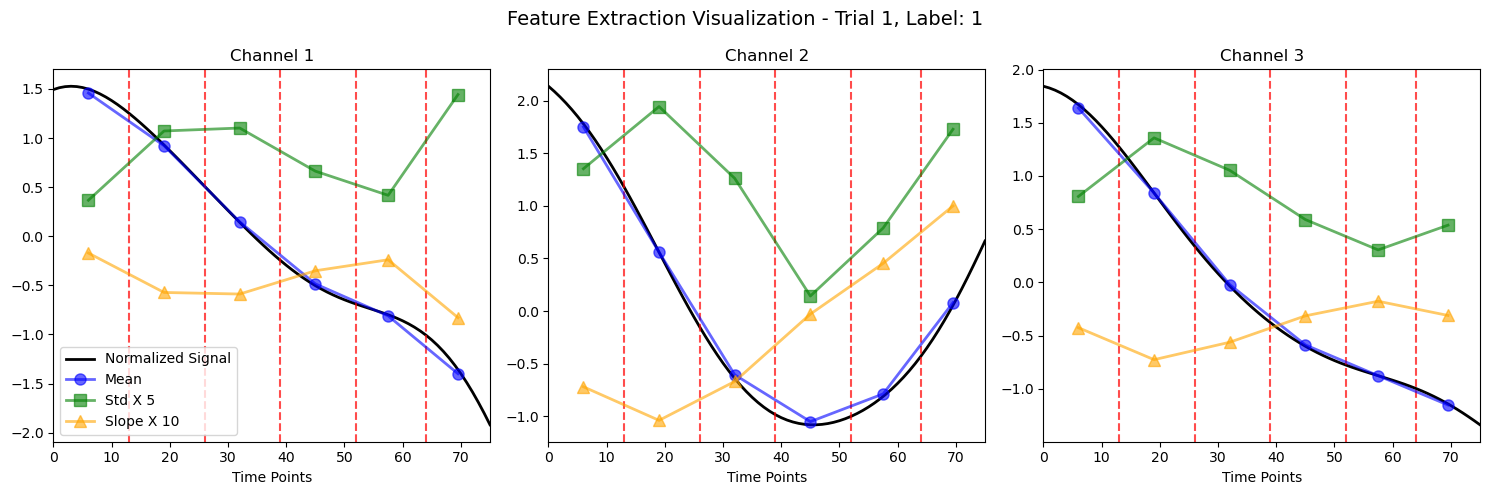


Extracted 1872 features total from normalized data:
6 windows X 104 channels X 3 features = 1872


In [5]:
# Visualize for first trial and first 3 channels
trial_idx = 0
channels = [0, 1, 2]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(
    f"Feature Extraction Visualization - Trial {trial_idx+1}, Label: {y[trial_idx]}",
    fontsize=14,
)

n_time = X_norm.shape[2]
window_indices = np.array_split(np.arange(n_time), 6)
window_centers = [idx.mean() for idx in window_indices]

for ch_idx, ch in enumerate(channels):
    ax = axes[ch_idx]

    # Plot normalized original time series
    time_points = np.arange(n_time)
    ax.plot(
        time_points,
        X_norm[trial_idx, ch, :],
        "k-",
        linewidth=2,
        label="Normalized Signal",
    )

    # Add window boundaries
    for idx in window_indices[1:]:
        ax.axvline(idx[0], color="red", linestyle="--", alpha=0.7)

    # Extract features for this channel across windows
    mean_feats = []
    std_feats = []
    slope_feats = []

    for win, idx in enumerate(window_indices):
        mean_idx = win * X_norm.shape[1] * 3 + ch
        std_idx = win * X_norm.shape[1] * 3 + X_norm.shape[1] + ch
        slope_idx = win * X_norm.shape[1] * 3 + 2 * X_norm.shape[1] + ch

        mean_feats.append(X_features[trial_idx, mean_idx])
        std_feats.append(X_features[trial_idx, std_idx])
        slope_feats.append(X_features[trial_idx, slope_idx])

    # Plot features at window centers
    ax.plot(
        window_centers,
        mean_feats,
        color="blue",
        marker="o",
        markersize=8,
        linewidth=2,
        alpha=0.6,
        label="Mean",
    )
    ax.plot(
        window_centers,
        [s * 5 for s in std_feats],
        color="green",
        marker="s",
        markersize=8,
        linewidth=2,
        alpha=0.6,
        label="Std X 5",
    )
    ax.plot(
        window_centers,
        [s * 10 for s in slope_feats],
        color="orange",
        marker="^",
        markersize=8,
        linewidth=2,
        alpha=0.6,
        label="Slope X 10",
    )

    ax.set_title(f"Channel {ch+1}")
    ax.set_xlabel("Time Points")
    ax.set_xlim(0, n_time - 1)

    if ch_idx == 0:
        ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

print(f"\nExtracted {X_features.shape[1]} features total from normalized data:")
print(
    f"6 windows X {X_norm.shape[1]} channels X 3 features = {6 * X_norm.shape[1] * 3}"
)
